# MCDI505 · Semana 4 — Evaluación 2024 (anexo del informe ejecutivo)
**Estudiante:** Roberto Moncada ·
**Programa:** Magíster en Ciencia de Datos, UNAB Online
**Curso:** MCDI505, Unidad 3, Semana 4 ·
**Archivo:** `mcdi505_s4rmoncada_anexo_preliminar.ipynb` ·
**Fecha:** Octubre de 2026

<div style="border:2px dashed #b30338; border-left:8px solid #b30338; background:rgba(179,3,56,0.07); padding:10px 16px; border-radius:4px;">

**VERSIÓN PRELIMINAR (eliminar este recuadro antes de entregar).** Notebook preparado con el asistente a partir de `MCDI505_Sumativa4_instrucciones_v2.pdf`, porque la plantilla oficial `mcdi505_s4_plantilla.ipynb` (Canvas) aún no está en el repositorio. Cuando la tenga, traspasar este código a la plantilla y entregar **la plantilla ejecutada** como anexo.

- **Qué pide la instrucción:** reestimar el modelo de la Sumativa 3 con enero de 2015 a diciembre de 2023, pronosticar los 12 meses de 2024 con su intervalo al 95 % y compararlo con el naive estacional mediante RMSE, MAE y MASE.
- **Rol del anexo:** respalda las cifras del informe ejecutivo (PDF o DOCX, de 5 a 7 páginas); no se califica por separado.
- **Uso de IA:** el código es apoyo del asistente; las celdas **[AUTOR]** se redactan con mis palabras y el uso se declara en el informe.

</div>

## 0. Configuración y datos

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

df = pd.read_csv("consumo_electrico_litoral_depurado.csv", parse_dates=["fecha"], index_col="fecha")
df.index.freq = "MS"
y = df["consumo_gwh"]
log_y = np.log(y)

# Partición final: entrenamiento 2015-2023 (incluye la validación 2023) y prueba 2024, que se abre esta semana
H, S = 12, 12
log_train = log_y[:"2023-12"]
y_train, y_test = y[:"2023-12"], y["2024-01":"2024-12"]
X_train = df[["covid"]][:"2023-12"]
X_test = df[["covid"]].loc["2024-01":"2024-12"]
print(f"Entrenamiento: {y_train.index[0]:%Y-%m} a {y_train.index[-1]:%Y-%m} ({len(y_train)} meses) | "
      f"Prueba: {y_test.index[0]:%Y-%m} a {y_test.index[-1]:%Y-%m} ({len(y_test)} meses) | covid en 2024 = {int(X_test.values.sum())}")

Entrenamiento: 2015-01 a 2023-12 (108 meses) | Prueba: 2024-01 a 2024-12 (12 meses) | covid en 2024 = 0


## 1. Modelo seleccionado en la Sumativa 3, reestimado con 2015-2023

In [2]:
# Misma especificación de las Sumativas 2 y 3: SARIMA(0,1,1)(0,1,1)12 + covid, sobre el logaritmo del consumo
ORDEN = (0, 1, 1)
ORDEN_ESTACIONAL = (0, 1, 1, 12)

sarima = SARIMAX(log_train, exog=X_train, order=ORDEN, seasonal_order=ORDEN_ESTACIONAL).fit(disp=False)
inicio = ORDEN[1] + ORDEN_ESTACIONAL[1] * ORDEN_ESTACIONAL[3]
residuos = sarima.resid.iloc[inicio:]

print(f"AIC = {sarima.aic:.1f} | BIC = {sarima.bic:.1f} | residuos utilizables: {len(residuos)}")
print(sarima.summary().tables[1])
print(f"Efecto covid: {100 * (np.exp(sarima.params['covid']) - 1):.1f} % | "
      f"mín. |raíz MA| = {np.abs(sarima.maroots).min():.3f} (1 = frontera de invertibilidad)")

# Diagnóstico breve de los residuos (mismas pruebas que en las semanas 2 y 3)
lb = acorr_ljungbox(residuos, lags=[12, 24], model_df=2)
lm_p = het_arch(residuos, nlags=12)[1]
print(f"Ljung-Box (12 / 24, 2 parámetros MA descontados): p = {lb.lb_pvalue.iloc[0]:.3f} / {lb.lb_pvalue.iloc[1]:.3f} | "
      f"ARCH-LM (12): p = {lm_p:.3f}")

AIC = -350.3 | BIC = -340.1 | residuos utilizables: 95
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
covid         -0.0683      0.015     -4.580      0.000      -0.098      -0.039
ma.L1         -0.2675      0.078     -3.423      0.001      -0.421      -0.114
ma.S.L12      -0.9939      6.352     -0.156      0.876     -13.443      11.456
sigma2         0.0010      0.006      0.159      0.873      -0.012       0.014
Efecto covid: -6.6 % | mín. |raíz MA| = 1.001 (1 = frontera de invertibilidad)
Ljung-Box (12 / 24, 2 parámetros MA descontados): p = 0.541 / 0.383 | ARCH-LM (12): p = 0.450


**[AUTOR] Lectura del modelo reestimado**

> _Pendiente, con mis palabras. Preguntas guía: ¿cambiaron los coeficientes respecto de la Semana 3 (ma.L1 = −0,205; ma.S.L12 = −0,981; covid = −6,0 %)? ¿Los residuos siguen sin autocorrelación ni efectos ARCH? ¿El MA estacional sigue cerca de la frontera de invertibilidad?_

<div style="border:2px dashed #b30338; border-left:8px solid #b30338; background:rgba(179,3,56,0.07); padding:10px 16px; border-radius:4px;">

### [BORRADOR] Lectura del modelo reestimado (§1)

**En simple:** volví a ajustar el mismo modelo de la Semana 3, ahora con un año más de datos (2015-2023). Hay que ver si cambió y si sigue sano.

| Qué mirar | Semana 3 (2015-2022) | Ahora (2015-2023) | Qué significa |
|---|---|---|---|
| Efecto covid | −6,0 % | −6,6 % | La pandemia bajó el consumo en torno a un 6 %; la cifra casi no cambia |
| ma.L1 | −0,205 | −0,268 | Parecido; sigue siendo significativo (p = 0,001) |
| ma.S.L12 | −0,981 | −0,994 | **Más pegado a −1**: el MA estacional está prácticamente en la frontera de invertibilidad (raíz 1,001) |
| Ljung-Box (12 / 24) | 0,355 / 0,061 | 0,541 / 0,383 | Los residuos ahora se ven **más** como ruido blanco |
| ARCH-LM | 0,639 | 0,450 | Sigue sin volatilidad condicional |
| AIC | −300,9 | −350,3 | **No se comparan**: hay más datos, así que el AIC cambia por eso y no por el modelo |

**Ideas para mi texto:**
- El modelo se mantiene estable al agregar 2023: los coeficientes y el efecto covid cambian poco.
- Los residuos mejoran (Ljung-Box sube a 0,541 y 0,383) y sigue sin efectos ARCH.
- Ojo: ma.S.L12 ≈ −1 suele indicar que la estacionalidad es casi fija año a año. No invalida el pronóstico, pero hay que mencionarlo como limitación.
- El AIC no se compara con el de la Semana 3 porque la muestra es distinta.

_Borrador del asistente: ideas y cifras en lenguaje sencillo para **organizar** lo que voy a escribir. No copiar tal cual: redactar con mis palabras en la celda [AUTOR] y en el informe, y declarar el apoyo. **Borrar esta celda antes de entregar.**_

</div>

## 2. Pronóstico 2024 con intervalo al 95 % y comparación con el naive estacional

In [3]:
pron = sarima.get_forecast(H, exog=X_test)
media_log = pron.predicted_mean
ic_log = pron.conf_int(alpha=0.05)
sd_log = (ic_log.iloc[:, 1] - media_log) / 1.96

# Retransformación a GWh con la media corregida por sesgo, exp(μ + σ²/2), como en las Sumativas 2 y 3 (métricas comparables
# entre semanas); exp(μ), la mediana, se informa como referencia. Los intervalos se retransforman sin corrección.
pron_sarima = np.exp(media_log + sd_log ** 2 / 2)
pron_sarima_mediana = np.exp(media_log)
inf_95, sup_95 = np.exp(ic_log.iloc[:, 0]), np.exp(ic_log.iloc[:, 1])
naive = y["2023-01":"2023-12"].to_numpy()          # naive estacional: repite 2023


def metricas(real, pred, y_entrenamiento, m=S):
    """RMSE y MAE en GWh; MASE escalado por el MAE del naive estacional dentro del entrenamiento (Hyndman y Athanasopoulos, 2021, §5.8)."""
    e = np.asarray(real, float) - np.asarray(pred, float)
    yt = np.asarray(y_entrenamiento, float)
    escala = np.mean(np.abs(yt[m:] - yt[:-m]))
    return {"RMSE": float(np.sqrt(np.mean(e ** 2))), "MAE": float(np.mean(np.abs(e))), "MASE": float(np.mean(np.abs(e)) / escala)}


tabla = pd.DataFrame({
    "SARIMA(0,1,1)(0,1,1)12 + covid": metricas(y_test, pron_sarima, y_train),
    "Naive estacional": metricas(y_test, naive, y_train),
}).T
tabla["Cobertura IC 95 %"] = [np.mean((y_test >= inf_95) & (y_test <= sup_95)), np.nan]
tabla["Ancho medio IC (GWh)"] = [float(np.mean(sup_95 - inf_95)), np.nan]
print("Tabla A1. Prueba 2024: RMSE y MAE en GWh (media corregida por sesgo, como en las Sumativas 2 y 3); MASE escalado por el naive estacional de 2015-2023")
display(tabla.round(3).astype(object).where(tabla.notna(), "—"))

m_med = metricas(y_test, pron_sarima_mediana, y_train)
print(f"Referencia sin corrección de sesgo (mediana, exp(μ)): RMSE = {m_med['RMSE']:.2f} | "
      f"MAE = {m_med['MAE']:.2f} | MASE = {m_med['MASE']:.3f}")

error = y_test.to_numpy() - pron_sarima.to_numpy()
print(f"Errores del SARIMA en 2024 (real - pronóstico): media = {error.mean():+.2f} GWh "
      f"({100 * error.mean() / y_test.mean():+.1f} % del consumo medio de 2024, {y_test.mean():.2f} GWh) | "
      f"meses con error positivo = {(error > 0).sum()}/{H}")

Tabla A1. Prueba 2024: RMSE y MAE en GWh (media corregida por sesgo, como en las Sumativas 2 y 3); MASE escalado por el naive estacional de 2015-2023


,RMSE,MAE,MASE,Cobertura IC 95 %,Ancho medio IC (GWh)
"SARIMA(0,1,1)(0,1,1)12 + covid",4.866,3.998,0.614,1.000,29.716
Naive estacional,8.193,6.666,1.024,—,—


Referencia sin corrección de sesgo (mediana, exp(μ)): RMSE = 4.96 | MAE = 4.07 | MASE = 0.626
Errores del SARIMA en 2024 (real - pronóstico): media = +2.89 GWh (+2.4 % del consumo medio de 2024, 120.05 GWh) | meses con error positivo = 9/12


In [4]:
detalle = pd.DataFrame({
    "Observado (GWh)": y_test,
    "SARIMA (GWh)": pron_sarima,
    "Inferior 95 %": inf_95,
    "Superior 95 %": sup_95,
    "Naive (GWh)": naive,
})
detalle["Error SARIMA"] = detalle["Observado (GWh)"] - detalle["SARIMA (GWh)"]
detalle["Error naive"] = detalle["Observado (GWh)"] - detalle["Naive (GWh)"]
detalle["Dentro del IC"] = (detalle["Observado (GWh)"] >= detalle["Inferior 95 %"]) & (detalle["Observado (GWh)"] <= detalle["Superior 95 %"])
detalle.index = detalle.index.strftime("%Y-%m")
print("Tabla A2. Pronóstico mensual de 2024")
display(detalle.round(2))

Tabla A2. Pronóstico mensual de 2024


,Observado (GWh),SARIMA (GWh),Inferior 95 %,Superior 95 %,Naive (GWh),Error SARIMA,Error naive,Dentro del IC
2024-01,145.820,138.500,129.530,147.920,132.060,7.320,13.760,True
2024-02,135.730,126.030,115.990,136.700,117.490,9.700,18.240,True
2024-03,116.510,117.380,106.580,128.970,114.880,-0.870,1.630,True
2024-04,107.290,104.540,93.800,116.150,99.530,2.750,7.760,True
2024-05,111.660,104.210,92.510,116.970,105.070,7.450,6.590,True
2024-06,112.600,109.490,96.240,124.040,109.910,3.110,2.690,True
2024-07,119.200,114.350,99.590,130.660,111.980,4.850,7.220,True
2024-08,115.220,112.800,97.400,129.940,107.310,2.420,7.910,True
2024-09,110.390,108.370,92.810,125.780,106.150,2.020,4.240,True
2024-10,111.000,109.310,92.880,127.790,106.610,1.690,4.390,True


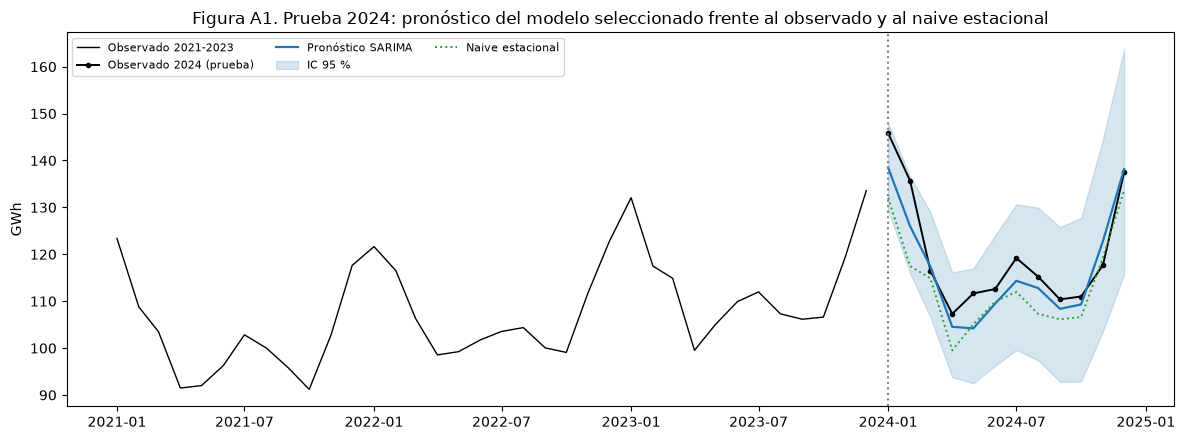

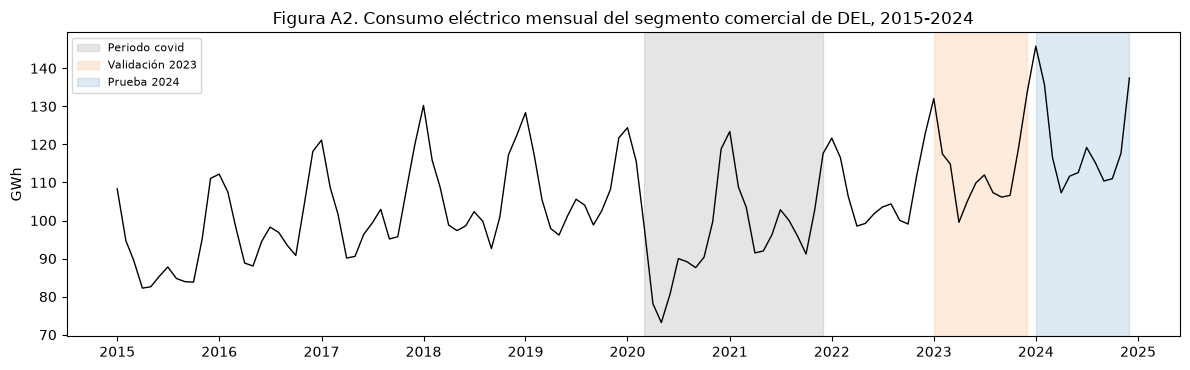

In [5]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(y["2021-01":"2023-12"].index, y["2021-01":"2023-12"], color="black", lw=1, label="Observado 2021-2023")
ax.plot(y_test.index, y_test, color="black", lw=1.4, marker="o", ms=3, label="Observado 2024 (prueba)")
ax.plot(y_test.index, pron_sarima, color="tab:blue", lw=1.6, label="Pronóstico SARIMA")
ax.fill_between(y_test.index, inf_95, sup_95, color="tab:blue", alpha=0.18, label="IC 95 %")
ax.plot(y_test.index, naive, color="tab:green", ls=":", lw=1.4, label="Naive estacional")
ax.axvline(pd.Timestamp("2024-01-01"), color="grey", ls=":")
ax.set_ylabel("GWh"); ax.set_title("Figura A1. Prueba 2024: pronóstico del modelo seleccionado frente al observado y al naive estacional")
ax.legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(y.index, y, color="black", lw=1)
ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-01"), color="grey", alpha=0.2, label="Periodo covid")
ax.axvspan(pd.Timestamp("2023-01-01"), pd.Timestamp("2023-12-01"), color="tab:orange", alpha=0.15, label="Validación 2023")
ax.axvspan(pd.Timestamp("2024-01-01"), pd.Timestamp("2024-12-01"), color="tab:blue", alpha=0.15, label="Prueba 2024")
ax.set_ylabel("GWh"); ax.set_title("Figura A2. Consumo eléctrico mensual del segmento comercial de DEL, 2015-2024")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**[AUTOR] Lectura de la prueba 2024**

> _Pendiente, con mis palabras. Preguntas guía: ¿el SARIMA supera al naive estacional en RMSE, MAE y MASE? (MASE < 1 significa un error menor que el del naive estacional dentro del entrenamiento). ¿Cuántos meses quedan dentro del IC 95 %? ¿Persiste el sesgo de nivel de 2023 (+6,40 GWh, 12/12 errores positivos) o se corrigió al incluir 2023 en el entrenamiento? ¿Qué significa el error medio para la compra de energía de DEL?_

<div style="border:2px dashed #b30338; border-left:8px solid #b30338; background:rgba(179,3,56,0.07); padding:10px 16px; border-radius:4px;">

### [BORRADOR] Lectura de la prueba 2024 (§2)

**En simple:** 2024 fue el «examen final». Era un año que el modelo nunca vio. Lo comparé con el naive estacional, que copia el consumo de 2023 mes a mes.

**Cifras clave (Tabla A1 y Figura A1; media corregida por sesgo, como en las semanas 2 y 3):**

| | SARIMA | Naive | Diferencia |
|---|---|---|---|
| RMSE (GWh) | 4,87 | 8,19 | El SARIMA se equivoca **40,6 % menos** |
| MAE (GWh) | 4,00 | 6,67 | **40,0 % menos**; el error típico es ≈ 3,3 % del consumo medio de 2024 (120,05 GWh) |
| MASE | 0,61 | 1,02 | Menor que 1: el SARIMA le gana a la referencia; el naive no |
| IC 95 % | 12/12 meses dentro | — | Ancho medio de 29,7 GWh (≈ 25 % del nivel) |

**Ideas para mi texto:**
- **Por qué el naive falla tanto en 2024:** el consumo de 2024 creció ≈ 5,6 % sobre 2023 (de 113,66 a 120,05 GWh de media) y el naive, al copiar 2023, queda bajo en 11 de 12 meses. Sus peores errores son enero (+13,8) y febrero (+18,2 GWh).
- **El sesgo bajó a menos de la mitad:** en 2023 el SARIMA subestimó 12/12 meses (+6,40 GWh); en 2024 subestima 9/12 meses, con +2,89 GWh de media (2,4 % del consumo). Agregar 2023 al entrenamiento ayudó a corregir el nivel.
- **Dónde se equivoca más:** febrero (+9,7), mayo (+7,5) y enero (+7,3 GWh). En noviembre sobreestima (−5,1 GWh).
- **El intervalo funcionó:** los 12 meses quedaron dentro, igual que en 2023. Es confiable, pero ancho.
- **Para DEL:** el pronóstico mensual se equivoca ≈ 4 GWh por mes; todavía tiende a quedarse un poco corto, y eso importa para la compra de energía.
- Sin la corrección de sesgo (mediana, exp(μ)) las cifras son casi iguales (RMSE 4,96; MAE 4,07): la conclusión no cambia.

_Borrador del asistente: ideas y cifras en lenguaje sencillo para **organizar** lo que voy a escribir. No copiar tal cual: redactar con mis palabras en la celda [AUTOR] y en el informe, y declarar el apoyo. **Borrar esta celda antes de entregar.**_

</div>

## 3. Evidencia acumulada, semanas 2 a 4 (insumo para el informe)

In [6]:
# Cifras de las semanas 2 y 3 copiadas de los notebooks entregados; las de 2024 se calculan arriba
m24, n24 = tabla.iloc[0], tabla.iloc[1]
evidencia = pd.DataFrame([
    ("S2", "Transformación y diferenciación", "log; d = 1, D = 1 (ADF p < 0,001; ACF(12) = −0,30)"),
    ("S2", "Selección entre 7 candidatos", "B: AIC −300,9; RMSE móvil 7,11 frente a 7,72 GWh del naive"),
    ("S2", "Validación 2023 (corrección de sesgo)", "RMSE 6,85 frente a 7,26; MAE 6,40 frente a 6,53 GWh"),
    ("S2", "Residuos", "Ljung-Box p = 0,355 / 0,061; ARCH-LM p = 0,639; cobertura móvil 94,4 %"),
    ("S3", "Memoria larga", "H = 0,652 (d = 0,152); el 37 % de los ruidos blancos supera ese valor; ARFIMA: ΔRMSE +0,21 GWh"),
    ("S3", "Volatilidad", "ARCH-LM p = 0,639; GARCH α = 0,066, α + β = 0,509; bandas 12/12, igual que el SARIMA"),
    ("S3", "Validación 2023 (media corregida)", "SARIMA 6,85 / 6,40; SARIMA + ARFIMA 7,06 / 6,64; naive 7,26 / 6,53 GWh"),
    ("S3", "Sesgo 2023", "12/12 errores positivos; +6,40 GWh (5,6 % del consumo medio)"),
    ("S4", "Prueba 2024: SARIMA", f"RMSE {m24['RMSE']:.2f}; MAE {m24['MAE']:.2f}; MASE {m24['MASE']:.3f}; "
                                  f"cobertura {round(m24['Cobertura IC 95 %'] * H)}/{H}"),
    ("S4", "Prueba 2024: naive estacional", f"RMSE {n24['RMSE']:.2f}; MAE {n24['MAE']:.2f}; MASE {n24['MASE']:.3f}"),
    ("S4", "Sesgo 2024", f"{error.mean():+.2f} GWh; {(error > 0).sum()}/{H} errores positivos"),
], columns=["Semana", "Decisión o prueba", "Evidencia"])
print("Tabla A3. Evidencia cuantitativa acumulada (para la Tabla 1 del informe)")
display(evidencia.style.hide(axis="index"))

Tabla A3. Evidencia cuantitativa acumulada (para la Tabla 1 del informe)


Semana,Decisión o prueba,Evidencia
S2,Transformación y diferenciación,"log; d = 1, D = 1 (ADF p < 0,001; ACF(12) = −0,30)"
S2,Selección entre 7 candidatos,"B: AIC −300,9; RMSE móvil 7,11 frente a 7,72 GWh del naive"
S2,Validación 2023 (corrección de sesgo),"RMSE 6,85 frente a 7,26; MAE 6,40 frente a 6,53 GWh"
S2,Residuos,"Ljung-Box p = 0,355 / 0,061; ARCH-LM p = 0,639; cobertura móvil 94,4 %"
S3,Memoria larga,"H = 0,652 (d = 0,152); el 37 % de los ruidos blancos supera ese valor; ARFIMA: ΔRMSE +0,21 GWh"
S3,Volatilidad,"ARCH-LM p = 0,639; GARCH α = 0,066, α + β = 0,509; bandas 12/12, igual que el SARIMA"
S3,Validación 2023 (media corregida),"SARIMA 6,85 / 6,40; SARIMA + ARFIMA 7,06 / 6,64; naive 7,26 / 6,53 GWh"
S3,Sesgo 2023,"12/12 errores positivos; +6,40 GWh (5,6 % del consumo medio)"
S4,Prueba 2024: SARIMA,RMSE 4.87; MAE 4.00; MASE 0.614; cobertura 12/12
S4,Prueba 2024: naive estacional,RMSE 8.19; MAE 6.67; MASE 1.024


<div style="border:2px dashed #b30338; border-left:8px solid #b30338; background:rgba(179,3,56,0.07); padding:10px 16px; border-radius:4px;">

### [BORRADOR] Ideas para ordenar el informe ejecutivo (§3)

**En simple:** el informe cuenta una historia en tres partes. Abajo, qué va en cada una y con qué cifra (la rúbrica pide que todo vaya con evidencia).

**1. Síntesis: problema, datos, metodología y solución** (criterio 1; para gerencia y operaciones)
- **Problema:** DEL necesita saber cuánta energía va a consumir su segmento comercial cada mes para planificar la compra.
- **Datos:** 120 meses (2015-2024), depurados, con el periodo covid marcado (Figura A2).
- **Cómo lo hice:** S1 limpieza → S2 modelos clásicos (7 candidatos) → S3 pruebo modelos avanzados (memoria larga y volatilidad) → S4 examen final con 2024.
- **Solución:** un SARIMA en logaritmos con un indicador covid; en 2024 se equivoca ≈ 4 GWh por mes (3,3 %) y le gana al naive en ≈ 40 %.

**2. Sustento técnico** (criterio 2; Tabla A3 como base de una tabla del informe)
- **Por qué este modelo y no otro:** en la S2 fue el único candidato que superó al naive y tuvo residuos limpios.
- **Por qué no ARFIMA:** H = 0,652 parece memoria larga, pero con 83 datos el 37 % de los ruidos blancos da un valor igual o mayor; además, empeoró el RMSE (+0,21 GWh).
- **Por qué no GARCH:** ARCH-LM p = 0,639; α + β = 0,509 (baja); las bandas son iguales a las del SARIMA.
- **Prueba 2024:** confirma la elección: MASE 0,61 frente a 1,02 del naive, y 12/12 meses dentro del intervalo.
- **Métricas comparables:** las tres semanas usan la media corregida por sesgo, exp(μ + σ²/2) (validación 2023: 6,85 / 6,40 GWh).

**3. Conclusiones y recomendaciones para la Gerencia** (criterio 3; cada una con su cifra)
- Usar el pronóstico SARIMA como base de la compra mensual (error típico ≈ 4 GWh, 3,3 %).
- Usar el límite superior del IC 95 % como margen de seguridad (cubrió 12/12 meses en 2023 y en 2024).
- Reestimar el modelo cada año con el dato nuevo (agregar 2023 bajó el sesgo de +6,40 a +2,89 GWh).
- Vigilar el sesgo mes a mes: todavía subestima 9 de 12 meses.
- **Limitaciones:** solo 12 meses de prueba; el MA estacional está en el límite (−0,994); el covid es un solo indicador; no usa temperatura ni clientes (posible SARIMAX).

**Figuras sugeridas:** A2 (la serie completa) para la síntesis y A1 (el pronóstico 2024) para el sustento. Sin código en el informe.

_Borrador del asistente: ideas y cifras en lenguaje sencillo para **organizar** lo que voy a escribir. No copiar tal cual: redactar con mis palabras en la celda [AUTOR] y en el informe, y declarar el apoyo. **Borrar esta celda antes de entregar.**_

</div>

## Para el informe ejecutivo (no forma parte del anexo final)

<div style="border:2px dashed #b30338; border-left:8px solid #b30338; background:rgba(179,3,56,0.07); padding:10px 16px; border-radius:4px;">

**Lista de verificación de la Sumativa 4** (eliminar antes de entregar):

- [ ] Informe en **PDF o DOCX de 5 a 7 páginas**, nombre `mcdi505_s4rmoncada`
- [ ] Estructura: portada o encabezado → síntesis (problema, datos, metodología y solución) → sustento técnico → conclusiones y recomendaciones → referencias → declaración de IA
- [ ] **Sin código**: figuras numeradas (A1 y A2 sirven de base), tablas reformateadas (A1 y A3) e interpretación en prosa
- [ ] Criterio 2: evidencia de las semanas 2 a 4 (dependencia temporal, volatilidad, métricas 2023 y 2024) y explicación con cifras de por qué ARFIMA y GARCH no aportaron
- [ ] Criterio 3: recomendaciones accionables para la Gerencia de DEL, cada una con su cifra, más limitaciones y alcances
- [ ] Incorporar la retroalimentación de la Formativa 4
- [ ] Anexo: **la plantilla oficial ejecutada** desde un kernel reiniciado
- [ ] Declaración de uso de IA (herramienta, partes y verificación)
- [ ] Entrega antes de las 23:59 del domingo de la Semana 4

Esquema y banco de evidencia: `docs/esquema_informe_s4rmoncada.md`.

</div>

## Referencias (APA)

Hyndman, R. J., y Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3.ª ed.). OTexts. https://otexts.com/fpp3/

Seabold, S., y Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. En S. van der Walt y J. Millman (Eds.), *Proceedings of the 9th Python in Science Conference* (pp. 92–96). https://doi.org/10.25080/Majora-92bf1922-011

Universidad Andrés Bello. (s. f.). *MCDI505 — Análisis de series de tiempo: Caso transversal del curso* [Material de curso]. UNAB Online.